
--- water_0 ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: -0.11 – 4.34

--- water_2 ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: -0.11 – 19.71


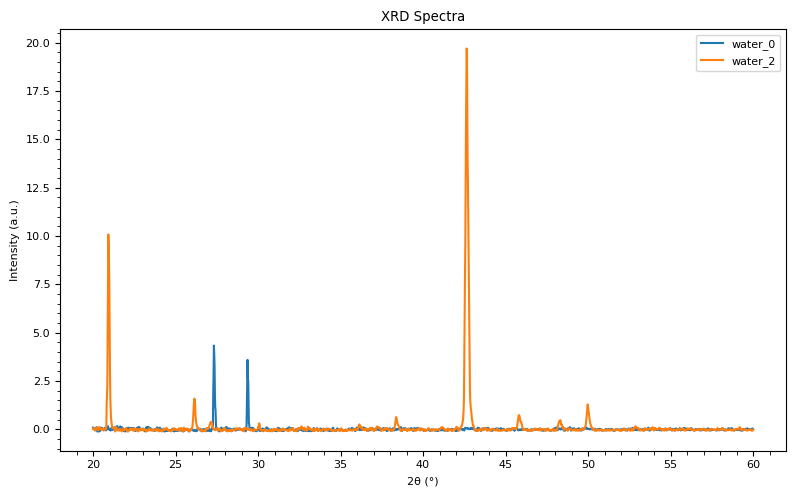

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    # "no_protein": "/home/pkwon2/aragonite/raman/mg_aragonite/water_0.xy",
    # "bsa": "/home/pkwon2/aragonite/raman/mg_aragonite/bsa_0.xy",
    # "f4": "/home/pkwon2/aragonite/raman/mg_aragonite/f4_0.xy",
    # "fd31": "/home/pkwon2/aragonite/raman/mg_aragonite/fd31_0.xy",
    "water_0": "/home/pkwon2/aragonite/raman/mg_aragonite/water_0.xy",
    "water_2": "/home/pkwon2/aragonite/raman/mg_aragonite/water_2.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 45
    mask = (x >= 20) & (x <= 60)
    x = x[mask]
    y = y[mask]

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

# Major ticks every 5°
plt.xticks(np.arange(20, 65, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save high-resolution outputs (raster + vector)
out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")  # vector, best for papers

plt.show()

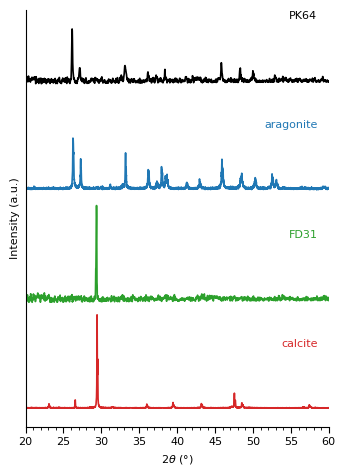

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "PK64": "/home/pkwon2/aragonite/raman/mg_aragonite/f4_0.xy",
    "aragonite": "/home/pkwon2/aragonite/raman/mg_aragonite/Aragonite_R060195.xy",
    "FD31": "/home/pkwon2/aragonite/raman/mg_aragonite/fd31_0.xy",
    "calcite": "/home/pkwon2/aragonite/raman/mg_aragonite/Calcite_R050130.xy",
}

# Order for plotting (top to bottom)
plot_order = ["PK64", "aragonite", "FD31", "calcite"]

# Colors for each trace
colors = {
    "PK64": "black",
    "aragonite": "tab:blue",
    "FD31": "tab:green",
    "calcite": "tab:red",
}

# Vertical offsets for stacked plotting
offset_step = 3.4

# Nature-style figure settings
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
})

fig, ax = plt.subplots(figsize=(3.5, 4.8))

for i, label in enumerate(plot_order):
    path = file_paths[label]

    # Load data
    data = np.loadtxt(path)
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 60
    mask = (x >= 20) & (x <= 60)
    x = x[mask]
    y = y[mask]

    # Normalize selected traces
    if label == "calcite":
        y = y / y.max() * 2.9
    elif label == "aragonite":
        y = y / y.max() * 1.6

    # Vertical offset for stacking
    offset = (len(plot_order) - 1 - i) * offset_step
    y_stacked = y + offset

    # Plot stacked trace
    ax.plot(x, y_stacked, linewidth=1.2, color=colors[label])

    # Put label on the right side
    ax.text(
        58.5,
        offset + 2,
        label,
        va="center",
        ha="right",
        fontsize=8,
        color=colors[label]
    )

# Axes labels
ax.set_xlabel(r"2$\theta$ (°)")
ax.set_ylabel("Intensity (a.u.)")

# X-axis ticks
ax.set_xlim(20, 60)
ax.set_xticks(np.arange(20, 61, 5))
ax.set_xticks(np.arange(20, 61, 1), minor=True)

# Remove y ticks for clean stacked presentation
ax.set_yticks([])

# Tick styling
ax.tick_params(axis="x", which="major", length=4, direction="out")
ax.tick_params(axis="x", which="minor", length=2, direction="out")
ax.tick_params(axis="y", which="both", length=0)

# Clean up spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save high-resolution outputs
out_base = "stacked_xrd_colored_right_labels"
fig.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
fig.savefig(f"{out_base}.pdf", bbox_inches="tight", pad_inches=0.02)

plt.show()


--- f4 ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: -0.11 – 4.60

--- aragonite ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: -0.11 – 4.09


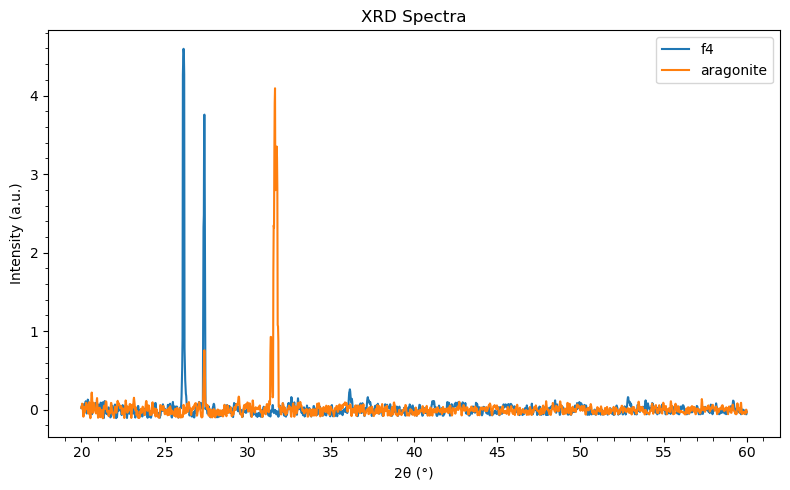

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    # "no_protein": "/home/pkwon2/aragonite/raman/mg_aragonite/water_0.xy",
    # "bsa_0": "/home/pkwon2/aragonite/raman/mg_aragonite/bsa_0.xy",
    "f4": "/home/pkwon2/aragonite/raman/mg_aragonite/f4_0.xy",
    "aragonite": "/home/pkwon2/aragonite/raman/mg_aragonite/f4_1_aragonite.xy",
    # "fd31": "/home/pkwon2/aragonite/raman/mg_aragonite/fd31_0.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 45
    mask = (x >= 20) & (x <= 60)
    x = x[mask]
    y = y[mask]

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

# Major ticks every 5°
plt.xticks(np.arange(20, 65, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save high-resolution outputs (raster + vector)
out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")  # vector, best for papers

plt.show()


--- bsa_1 ---
Number of data points: 501
x range: 20.00 – 30.00
y range: 0.00 – 0.25


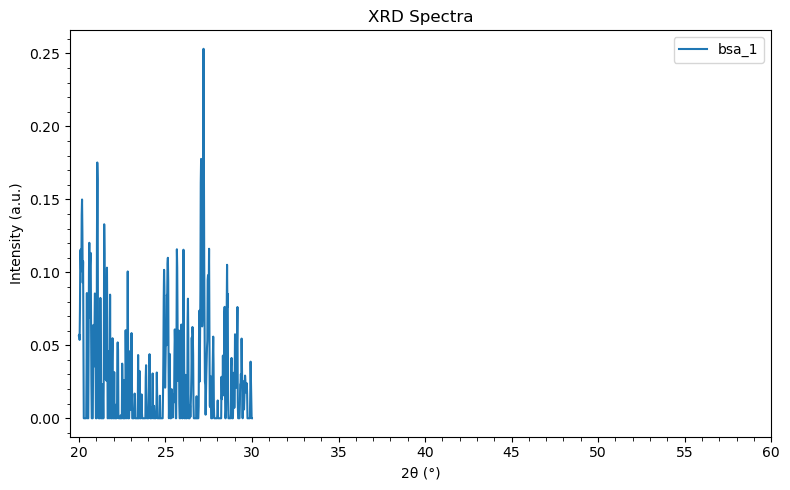

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "bsa_1": "/home/pkwon2/aragonite/raman/mg_aragonite/bsa_1.xy",
    "f5": "/home/pkwon2/aragonite/raman/mg_aragonite/f5_0.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    data = np.loadtxt(path)

    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 30
    mask = (x >= 20) & (x <= 30)
    x = x[mask]
    y = y[mask]

    # Remove values below 0 by clipping
    y = np.clip(y, 0, None)

    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    plt.plot(x, y, label=label)

plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

plt.xticks(np.arange(20, 65, 5))
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")

plt.show()


--- bsa_0 ---
Number of data points: 1651
x range: 20.00 – 53.00
y range: 0.00 – 0.21

--- bsa_1 ---
Number of data points: 1651
x range: 20.00 – 53.00
y range: 0.00 – 0.40


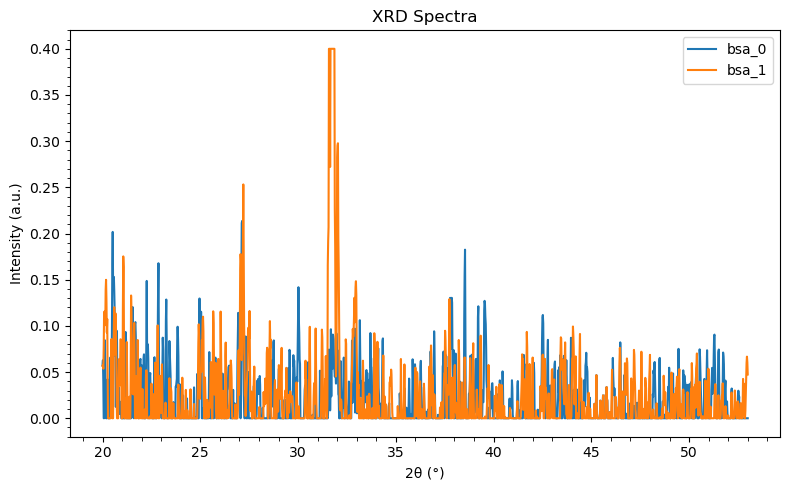

In [41]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "bsa_0": "/home/pkwon2/aragonite/raman/mg_aragonite/bsa_0.xy",
    "bsa_1": "/home/pkwon2/aragonite/raman/mg_aragonite/bsa_1.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    data = np.loadtxt(path)

    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 30
    mask = (x >= 20) & (x <= 53)
    x = x[mask]
    y = y[mask]

    # Clip: 0 <= y <= 0.4
    y = np.clip(y, 0, 0.4)

    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    plt.plot(x, y, label=label)

plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

plt.xticks(np.arange(20, 55, 5))
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")

plt.show()


--- no_protein ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: 0.00 – 4.34

--- bsa_0 ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: 0.00 – 0.31


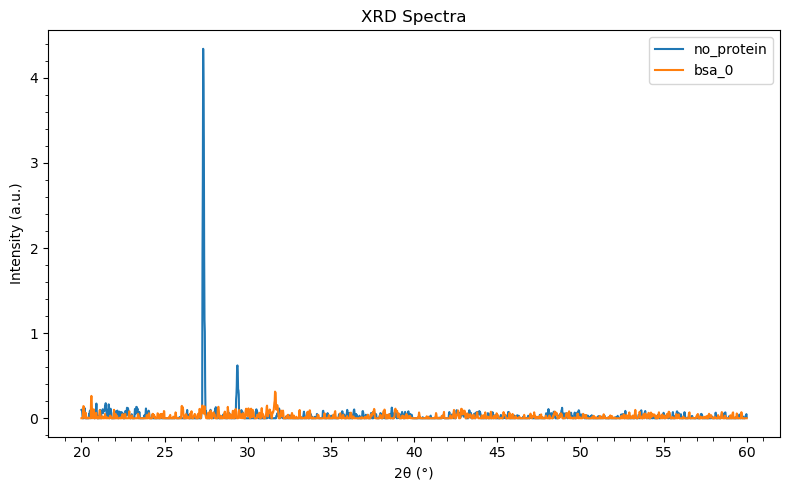

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "no_protein": "/home/pkwon2/aragonite/raman/mg_aragonite/water_0.xy",
    "bsa_0": "/home/pkwon2/aragonite/raman/mg_aragonite/bsa_0.xy",
    # "f4": "/home/pkwon2/aragonite/raman/mg_aragonite/f4_0.xy",
    # "f5": "/home/pkwon2/aragonite/raman/mg_aragonite/f5_0.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    data = np.loadtxt(path)

    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 30
    mask = (x >= 20) & (x <= 60)
    x = x[mask]
    y = y[mask]

    # Clip: 0 <= y <= 0.4
    y = np.clip(y, 0, 20)

    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    plt.plot(x, y, label=label)

plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

plt.xticks(np.arange(20, 65, 5))
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")

plt.show()


--- no_protein ---
Number of data points: 2001
x range: 20.00 – 60.00
Aragonite window: 27.0–28.0° 2θ
arag peak max (raw):   0.6340 at 27.320°
arag peak max (shown): 0.4000 at 27.300°

--- bsa ---
Number of data points: 2001
x range: 20.00 – 60.00
Aragonite window: 27.0–28.0° 2θ
arag peak max (raw):   0.1493 at 27.260°
arag peak max (shown): 0.1493 at 27.260°

--- fd31 ---
Number of data points: 2001
x range: 20.00 – 60.00
Aragonite window: 27.0–28.0° 2θ
arag peak max (raw):   0.4440 at 27.120°
arag peak max (shown): 0.4000 at 27.120°

--- f4 ---
Number of data points: 2001
x range: 20.00 – 60.00
Aragonite window: 27.0–28.0° 2θ
arag peak max (raw):   0.7577 at 27.400°
arag peak max (shown): 0.4000 at 27.360°


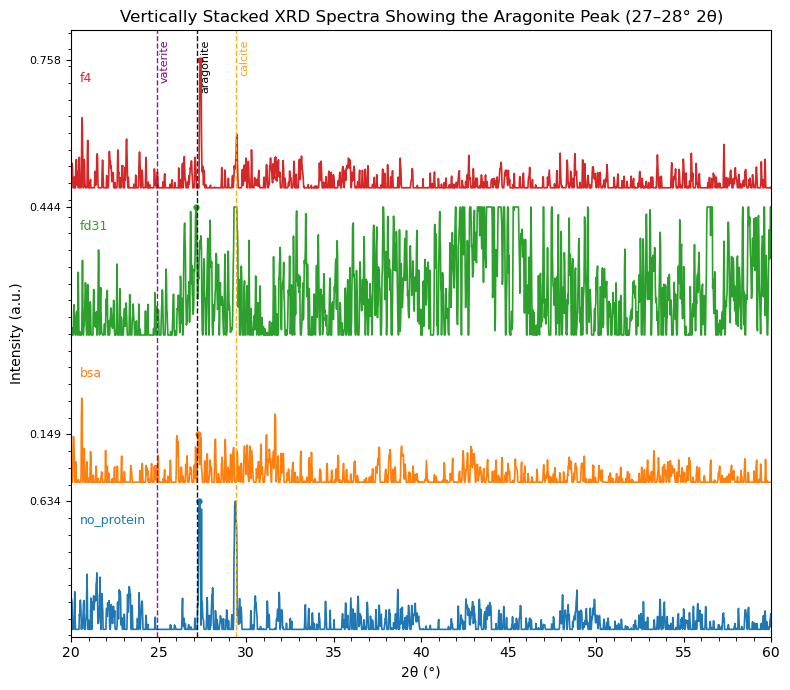

In [12]:
# import numpy as np
# import matplotlib.pyplot as plt

# # File paths for all spectra (order here = top-to-bottom order in the plot)
# file_paths = {
#     "no_protein": "/home/pkwon2/aragonite/raman/mg_aragonite/water_0.xy",
#     "bsa":        "/home/pkwon2/aragonite/raman/mg_aragonite/bsa_0.xy",
#     "f4":         "/home/pkwon2/aragonite/raman/mg_aragonite/f4_0.xy",
#     "f5":         "/home/pkwon2/aragonite/raman/mg_aragonite/f5_0.xy",
# }

# # Reference peak positions (2θ, degrees)
# vaterite_peaks  = [24.9]
# aragonite_peaks = [27.2]
# calcite_peaks   = [29.4]

# # ---- plotting settings ----
# x_min, x_max = 20, 60
# y_min, y_max = 0.0, 0.4
# offset = (y_max - y_min) * 1.15  # vertical gap between stacked spectra

# labels = list(file_paths.keys())
# n = len(labels)

# plt.figure(figsize=(8, 7))

# # Colors for the 4 spectra
# cmap = plt.get_cmap("tab10")
# trace_colors = [cmap(i) for i in range(n)]

# ax = plt.gca()

# # We'll put one y-tick per spectrum at the tallest (displayed) peak height,
# # and label it with the *raw* tallest peak value (before clipping).
# ytick_pos = []
# ytick_lbl = []

# # Plot stacked traces (reverse so first item appears on top)
# for i, label in enumerate(labels[::-1]):
#     path = file_paths[label]
#     data = np.loadtxt(path)

#     x = data[:, 0]
#     y = data[:, 1]

#     # Restrict to x-range
#     mask = (x >= x_min) & (x <= x_max)
#     x = x[mask]
#     y = y[mask]

#     # Tallest peak (raw, before clipping)
#     peak_raw = float(np.max(y)) if len(y) else np.nan

#     # Clip: 0 <= y <= 0.4 (for plotting)
#     y = np.clip(y, y_min, y_max)

#     # Tallest peak actually shown (after clipping)
#     peak_shown = float(np.max(y)) if len(y) else np.nan

#     # Apply vertical stacking offset
#     y_stacked = y + i * offset

#     print(f"\n--- {label} ---")
#     print(f"Number of data points: {len(x)}")
#     print(f"x range: {x.min():.2f} – {x.max():.2f}")
#     print(f"peak max (raw): {peak_raw:.4f}")
#     print(f"peak max (shown, clipped): {peak_shown:.4f}")

#     ax.plot(x, y_stacked, lw=1.2, color=trace_colors[i])
#     ax.text(
#         x_min + 0.5,
#         i * offset + (y_max * 0.85),
#         label,
#         va="center",
#         fontsize=9,
#         color=trace_colors[i],
#     )

#     # Add a y-axis tick at the tallest shown peak position, label with raw peak height
#     if len(y):
#         ytick_pos.append(i * offset + peak_shown)
#         ytick_lbl.append(f"{peak_raw:.3f}")

# # Add reference peak markers
# y_top = (n - 1) * offset + y_max

# def add_peak_lines(peaks, phase_label, color, linestyle="--", dx=0.18, y_frac=0.985):
#     """
#     dx: shift label to the right of the line (in degrees 2θ)
#     y_frac: vertical position in axes coords (0..1), keeps text inside the box
#     """
#     for p in peaks:
#         ax.axvline(p, color=color, linestyle=linestyle, lw=1.0, alpha=0.9)

#     for p in peaks:
#         if x_min <= p <= x_max:
#             ax.text(
#                 p + dx, y_frac, phase_label,
#                 transform=ax.get_xaxis_transform(),  # x in data units, y in axes fraction
#                 rotation=90,
#                 va="top", ha="left",
#                 fontsize=8, color=color,
#                 clip_on=True
#             )
#             break

# add_peak_lines(vaterite_peaks,  "vaterite",  color="purple", linestyle="--")
# add_peak_lines(aragonite_peaks, "aragonite", color="black",  linestyle="--")
# add_peak_lines(calcite_peaks,   "calcite",   color="orange", linestyle="--")

# ax.set_xlabel("2θ (°)")
# ax.set_ylabel("Tallest peak (a.u.)")  # tick labels are per-spectrum tallest peak values (raw)

# ax.set_title("XRD Spectra (Vertically Stacked)")

# ax.set_xlim(x_min, x_max)
# ax.set_ylim(-0.05 * offset, y_top + 0.20 * offset)

# ax.set_xticks(np.arange(20, 65, 5))
# ax.minorticks_on()
# ax.tick_params(axis="x", which="minor", length=3)

# # Put one y-tick per trace at its tallest (shown) peak, labeled with the raw tallest peak value
# ax.set_yticks(ytick_pos)
# ax.set_yticklabels(ytick_lbl, fontsize=8)

# plt.tight_layout()

# out_base = "aragonite_stacked_with_peaks"
# plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
# plt.savefig(f"{out_base}.pdf", bbox_inches="tight")

# plt.show()

import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra (order here = top-to-bottom order in the plot)
file_paths = {
    "f4":         "/home/pkwon2/aragonite/raman/mg_aragonite/f4_1_aragonite.xy",
    "fd31":         "/home/pkwon2/aragonite/raman/mg_aragonite/fd31_calcite.xy",
    "bsa":        "/home/pkwon2/aragonite/raman/mg_aragonite/bsa_10mM_caco3_80C_2h.xy",
    "no_protein": "/home/pkwon2/aragonite/raman/mg_aragonite/water_10mM_caco3_80C_2h.xy",
}

# Reference peak positions (2θ, degrees)
vaterite_peaks  = [24.9]
aragonite_peaks = [27.2]
calcite_peaks   = [29.4]

# ---- plotting settings ----
x_min, x_max = 20, 60
y_min, y_max = 0.0, 0.4
offset = (y_max - y_min) * 1.15  # vertical gap between stacked spectra

# Aragonite peak search window (degrees 2θ)
arag_lo, arag_hi = 27.0, 28.0

labels = list(file_paths.keys())
n = len(labels)

plt.figure(figsize=(8, 7))

# Colors for the 4 spectra
cmap = plt.get_cmap("tab10")
trace_colors = [cmap(i) for i in range(n)]

ax = plt.gca()

# One y-tick per spectrum at the aragonite-window peak height (shown),
# labeled by the raw aragonite-window peak value (before clipping).
ytick_pos = []
ytick_lbl = []

# Plot stacked traces (reverse so first item appears on top)
for i, label in enumerate(labels[::-1]):
    path = file_paths[label]
    data = np.loadtxt(path)

    x = data[:, 0]
    y = data[:, 1]

    # Restrict to x-range
    mask = (x >= x_min) & (x <= x_max)
    x = x[mask]
    y = y[mask]

    # ---- aragonite-window peak (raw, before clipping) ----
    mask_arag = (x >= arag_lo) & (x <= arag_hi)
    if np.any(mask_arag):
        x_ar = x[mask_arag]
        y_ar = y[mask_arag]

        idx_raw = int(np.argmax(y_ar))
        peak_arag_raw = float(y_ar[idx_raw])
        peak_arag_pos = float(x_ar[idx_raw])
    else:
        peak_arag_raw = np.nan
        peak_arag_pos = np.nan

    # Clip for plotting
    y_clip = np.clip(y, y_min, y_max)

    # ---- aragonite-window peak (shown, after clipping) ----
    if np.any(mask_arag):
        y_ar_shown = y_clip[mask_arag]
        idx_shown = int(np.argmax(y_ar_shown))
        peak_arag_shown = float(y_ar_shown[idx_shown])

        # use the *same position* array x_ar for shown-peak position
        peak_arag_pos_shown = float(x_ar[idx_shown])
    else:
        peak_arag_shown = np.nan
        peak_arag_pos_shown = np.nan

    # Apply vertical stacking offset
    y_stacked = y_clip + i * offset

    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    if len(x):
        print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"Aragonite window: {arag_lo:.1f}–{arag_hi:.1f}° 2θ")
    print(f"arag peak max (raw):   {peak_arag_raw:.4f} at {peak_arag_pos:.3f}°")
    print(f"arag peak max (shown): {peak_arag_shown:.4f} at {peak_arag_pos_shown:.3f}°")

    ax.plot(x, y_stacked, lw=1.2, color=trace_colors[i])
    ax.text(
        x_min + 0.5,
        i * offset + (y_max * 0.85),
        label,
        va="center",
        fontsize=9,
        color=trace_colors[i],
    )

    # Mark the aragonite-window max on the trace (optional)
    if np.isfinite(peak_arag_pos_shown):
        ax.plot(
            peak_arag_pos_shown,
            i * offset + peak_arag_shown,
            marker="o",
            ms=3.5,
            color=trace_colors[i],
        )

    # Add a y-axis tick at the aragonite-window peak position, label with raw peak height
    if np.isfinite(peak_arag_shown):
        ytick_pos.append(i * offset + peak_arag_shown)
        ytick_lbl.append(f"{peak_arag_raw:.3f}")
    else:
        # If no data in 27–28 window, still put a placeholder tick near the baseline
        ytick_pos.append(i * offset + 0.0)
        ytick_lbl.append("nan")

# Add reference peak markers
y_top = (n - 1) * offset + y_max

def add_peak_lines(peaks, phase_label, color, linestyle="--", dx=0.18, y_frac=0.985):
    for p in peaks:
        ax.axvline(p, color=color, linestyle=linestyle, lw=1.0, alpha=0.9)
    for p in peaks:
        if x_min <= p <= x_max:
            ax.text(
                p + dx, y_frac, phase_label,
                transform=ax.get_xaxis_transform(),
                rotation=90,
                va="top", ha="left",
                fontsize=8, color=color,
                clip_on=True
            )
            break

add_peak_lines(vaterite_peaks,  "vaterite",  color="purple", linestyle="--")
add_peak_lines(aragonite_peaks, "aragonite", color="black",  linestyle="--")
add_peak_lines(calcite_peaks,   "calcite",   color="orange", linestyle="--")

ax.set_xlabel("2θ (°)")
ax.set_ylabel("Intensity (a.u.)")  # tick labels are raw peak values (27–28° window)
ax.set_title("Vertically Stacked XRD Spectra Showing the Aragonite Peak (27–28° 2θ)")

ax.set_xlim(x_min, x_max)
ax.set_ylim(-0.05 * offset, y_top + 0.20 * offset)

ax.set_xticks(np.arange(20, 65, 5))
ax.minorticks_on()
ax.tick_params(axis="x", which="minor", length=3)

ax.set_yticks(ytick_pos)
ax.set_yticklabels(ytick_lbl, fontsize=8)

plt.tight_layout()

out_base = "aragonite_stacked_aragpeak_27to28"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")

plt.show()


--- fd31 ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: -0.18 – 1.18

--- no_protein ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: -0.11 – 0.63


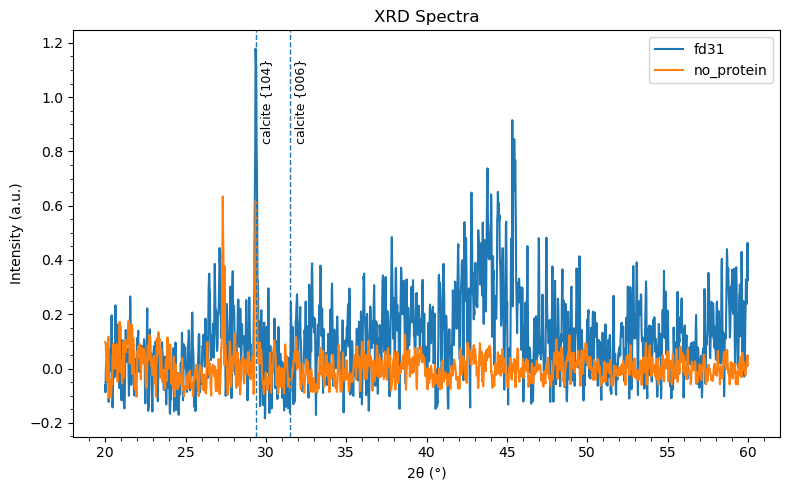

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    # "f4":         "/home/pkwon2/aragonite/raman/mg_aragonite/f4_1_aragonite.xy",
    "fd31":         "/home/pkwon2/aragonite/raman/mg_aragonite/fd31_calcite.xy",
    # "bsa":        "/home/pkwon2/aragonite/raman/mg_aragonite/bsa_10mM_caco3_80C_2h.xy",
    "no_protein": "/home/pkwon2/aragonite/raman/mg_aragonite/water_10mM_caco3_80C_2h.xy",
}

# Calcite facet reference lines (2θ, degrees)
calcite_refs = [
    (29.4, r"calcite {104}"),
    (31.5, r"calcite {006}"),
]

plt.figure(figsize=(8, 5))

ymax_seen = -np.inf

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 60
    mask = (x >= 20) & (x <= 60)
    x = x[mask]
    y = y[mask]

    # Track max y for label placement
    if len(y) > 0:
        ymax_seen = max(ymax_seen, np.max(y))

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# --- Add vertical reference lines + labels ---
if not np.isfinite(ymax_seen):
    ymax_seen = 1.0  # fallback in case something went wrong / empty data

label_y = 0.97 * ymax_seen  # near the top
for x0, txt in calcite_refs:
    plt.axvline(x0, linestyle="--", linewidth=1)
    plt.text(
        x0 + 0.25,          # shift right of the line
        label_y,
        txt,
        rotation=90,
        va="top",
        ha="left",
        fontsize=9,
        clip_on=True
    )

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

# Major ticks every 5°
plt.xticks(np.arange(20, 61, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save high-resolution outputs (raster + vector)
out_base = "xrd_array_vs_no_protein_vs_si_wafer"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")  # vector, best for papers

plt.show()

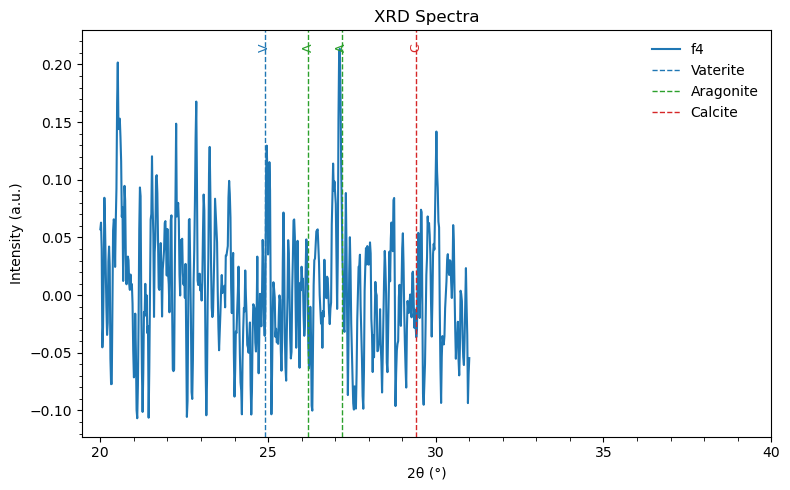

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "f4": "/home/pkwon2/aragonite/raman/mg_aragonite/bsa_0.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    data = np.loadtxt(path)

    x = data[:, 0]
    y = data[:, 1]

    # Restrict range
    mask = (x >= 20) & (x <= 31)
    x = x[mask]
    y = y[mask]

    plt.plot(x, y, label=label)

# ----------------------------
# Reference peak positions
# ----------------------------
vaterite_peaks = [24.9]
aragonite_peaks = [26.2, 27.2]
calcite_peaks = [29.4]

colors = {
    "vaterite": "tab:blue",
    "aragonite": "tab:green",
    "calcite": "tab:red",
}

ymax = plt.gca().get_ylim()[1]

# Vaterite
for p in vaterite_peaks:
    plt.axvline(
        p, color=colors["vaterite"], linestyle="--", linewidth=1,
        label="Vaterite" if p == vaterite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "V", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["vaterite"])

# Aragonite
for p in aragonite_peaks:
    plt.axvline(
        p, color=colors["aragonite"], linestyle="--", linewidth=1,
        label="Aragonite" if p == aragonite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "A", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["aragonite"])

# Calcite
for p in calcite_peaks:
    plt.axvline(
        p, color=colors["calcite"], linestyle="--", linewidth=1,
        label="Calcite" if p == calcite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "C", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["calcite"])

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")

plt.legend(frameon=False)

# Ticks
plt.xticks(np.arange(20, 65, 5))
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save outputs
out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")

plt.show()

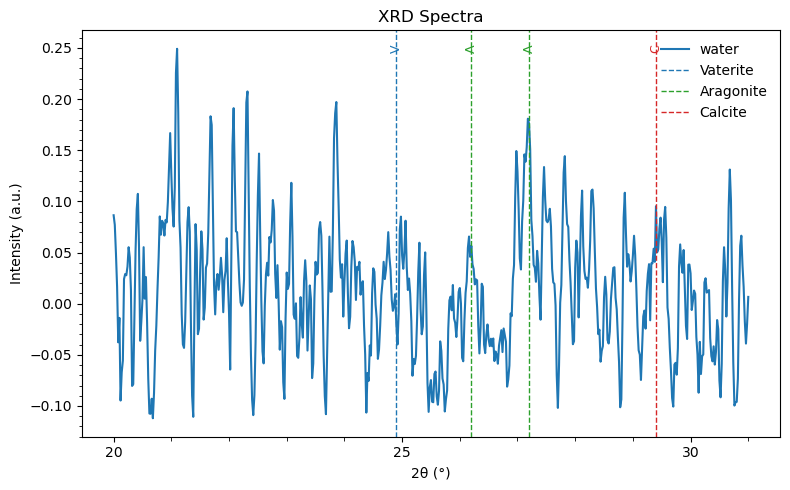

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "water": "/home/pkwon2/aragonite/raman/mg_aragonite/water.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    data = np.loadtxt(path)

    x = data[:, 0]
    y = data[:, 1]

    # Restrict range
    mask = (x >= 20) & (x <= 31)
    x = x[mask]
    y = y[mask]

    plt.plot(x, y, label=label)

# ----------------------------
# Reference peak positions
# ----------------------------
vaterite_peaks = [24.9]
aragonite_peaks = [26.2, 27.2]
calcite_peaks = [29.4]

colors = {
    "vaterite": "tab:blue",
    "aragonite": "tab:green",
    "calcite": "tab:red",
}

ymax = plt.gca().get_ylim()[1]

# Vaterite
for p in vaterite_peaks:
    plt.axvline(
        p, color=colors["vaterite"], linestyle="--", linewidth=1,
        label="Vaterite" if p == vaterite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "V", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["vaterite"])

# Aragonite
for p in aragonite_peaks:
    plt.axvline(
        p, color=colors["aragonite"], linestyle="--", linewidth=1,
        label="Aragonite" if p == aragonite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "A", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["aragonite"])

# Calcite
for p in calcite_peaks:
    plt.axvline(
        p, color=colors["calcite"], linestyle="--", linewidth=1,
        label="Calcite" if p == calcite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "C", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["calcite"])

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")

plt.legend(frameon=False)

# Ticks
plt.xticks(np.arange(20, 31, 5))
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save outputs
out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")

plt.show()

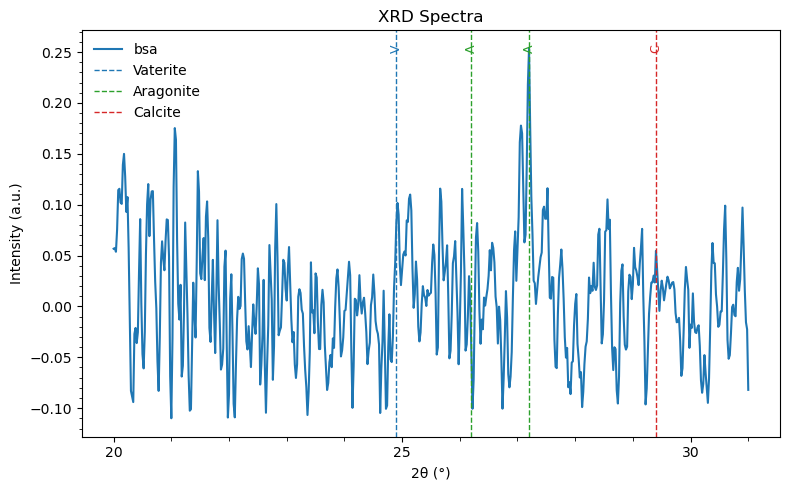

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "bsa": "/home/pkwon2/aragonite/raman/mg_aragonite/bsa.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    data = np.loadtxt(path)

    x = data[:, 0]
    y = data[:, 1]

    # Restrict range
    mask = (x >= 20) & (x <= 31)
    x = x[mask]
    y = y[mask]

    plt.plot(x, y, label=label)

# ----------------------------
# Reference peak positions
# ----------------------------
vaterite_peaks = [24.9]
aragonite_peaks = [26.2, 27.2]
calcite_peaks = [29.4]

colors = {
    "vaterite": "tab:blue",
    "aragonite": "tab:green",
    "calcite": "tab:red",
}

ymax = plt.gca().get_ylim()[1]

# Vaterite
for p in vaterite_peaks:
    plt.axvline(
        p, color=colors["vaterite"], linestyle="--", linewidth=1,
        label="Vaterite" if p == vaterite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "V", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["vaterite"])

# Aragonite
for p in aragonite_peaks:
    plt.axvline(
        p, color=colors["aragonite"], linestyle="--", linewidth=1,
        label="Aragonite" if p == aragonite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "A", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["aragonite"])

# Calcite
for p in calcite_peaks:
    plt.axvline(
        p, color=colors["calcite"], linestyle="--", linewidth=1,
        label="Calcite" if p == calcite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "C", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["calcite"])

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")

plt.legend(frameon=False)

# Ticks
plt.xticks(np.arange(20, 31, 5))
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save outputs
out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")

plt.show()


--- bsa ---
Number of data points: 551
x range: 20.00 – 31.00
y range: -0.11 – 0.25

--- no_protein ---
Number of data points: 551
x range: 20.00 – 31.00
y range: -0.11 – 0.25

--- f4 ---
Number of data points: 551
x range: 20.00 – 31.00
y range: -0.11 – 0.33


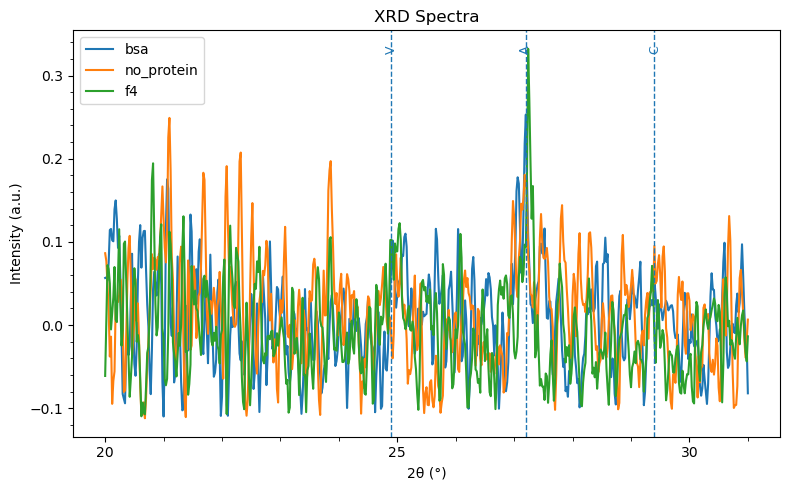

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "bsa": "/home/pkwon2/aragonite/raman/mg_aragonite/bsa.xy",
    "no_protein": "/home/pkwon2/aragonite/raman/mg_aragonite/water.xy",
    "f4": "/home/pkwon2/aragonite/raman/mg_aragonite/f4.xy",
    # "f5": "/home/pkwon2/aragonite/raman/mg_aragonite/f5.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 45
    mask = (x >= 20) & (x <= 31)
    x = x[mask]
    y = y[mask]

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

# ----------------------------
# Reference peak positions
# ----------------------------
vaterite_peaks = [24.9]
aragonite_peaks = [27.2]
calcite_peaks = [29.4]

colors = {
    "vaterite": "tab:blue",
    "aragonite": "tab:blue",
    "calcite": "tab:blue",
}

ymax = plt.gca().get_ylim()[1]

# Vaterite
for p in vaterite_peaks:
    plt.axvline(
        p, color=colors["vaterite"], linestyle="--", linewidth=1,
        label="Vaterite" if p == vaterite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "V", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["vaterite"])

# Aragonite
for p in aragonite_peaks:
    plt.axvline(
        p, color=colors["aragonite"], linestyle="--", linewidth=1,
        label="Aragonite" if p == aragonite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "A", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["aragonite"])

# Calcite
for p in calcite_peaks:
    plt.axvline(
        p, color=colors["calcite"], linestyle="--", linewidth=1,
        label="Calcite" if p == calcite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "C", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["calcite"])

# Major ticks every 5°
plt.xticks(np.arange(20, 31, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save high-resolution outputs (raster + vector)
out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")  # vector, best for papers

plt.show()


--- bsa ---
Number of data points: 551
x range: 20.00 – 31.00
y range: 0.00 – 0.25

--- no_protein ---
Number of data points: 551
x range: 20.00 – 31.00
y range: 0.00 – 0.25

--- f4 ---
Number of data points: 551
x range: 20.00 – 31.00
y range: 0.00 – 0.33


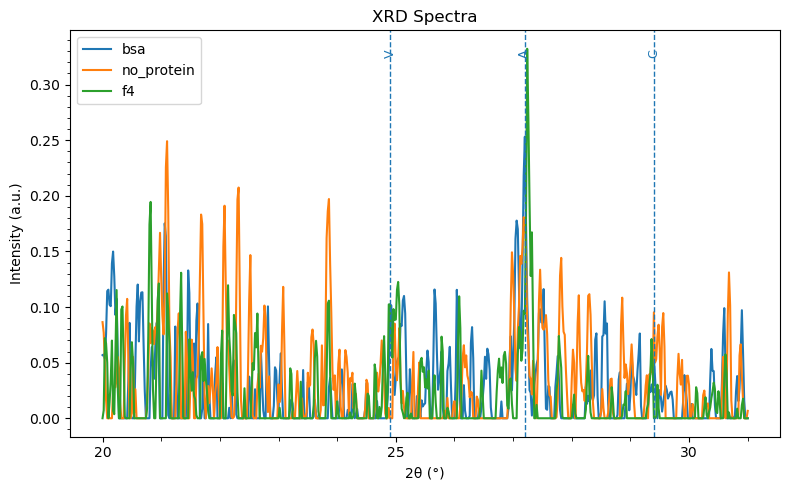

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# File paths for all spectra
# ----------------------------
file_paths = {
    "bsa": "/home/pkwon2/aragonite/raman/mg_aragonite/bsa.xy",
    "no_protein": "/home/pkwon2/aragonite/raman/mg_aragonite/water.xy",
    "f4": "/home/pkwon2/aragonite/raman/mg_aragonite/f4.xy",
    # "f5": "/home/pkwon2/aragonite/raman/mg_aragonite/f5.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # ----------------------------
    # Cut off values below 0
    # ----------------------------
    y = np.clip(y, 0, None)

    # Restrict to 20 ≤ x ≤ 31
    mask = (x >= 20) & (x <= 31)
    x = x[mask]
    y = y[mask]

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# ----------------------------
# Labels and title
# ----------------------------
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

# ----------------------------
# Reference peak positions
# ----------------------------
vaterite_peaks = [24.9]
aragonite_peaks = [27.2]
calcite_peaks = [29.4]

colors = {
    "vaterite": "tab:blue",
    "aragonite": "tab:blue",
    "calcite": "tab:blue",
}

ymax = plt.gca().get_ylim()[1]

# Vaterite
for p in vaterite_peaks:
    plt.axvline(
        p, color=colors["vaterite"], linestyle="--", linewidth=1,
        label="Vaterite" if p == vaterite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "V", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["vaterite"])

# Aragonite
for p in aragonite_peaks:
    plt.axvline(
        p, color=colors["aragonite"], linestyle="--", linewidth=1,
        label="Aragonite" if p == aragonite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "A", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["aragonite"])

# Calcite
for p in calcite_peaks:
    plt.axvline(
        p, color=colors["calcite"], linestyle="--", linewidth=1,
        label="Calcite" if p == calcite_peaks[0] else None
    )
    plt.text(p, ymax * 0.95, "C", rotation=90, va="top",
             ha="center", fontsize=9, color=colors["calcite"])

# ----------------------------
# Ticks
# ----------------------------
# Major ticks every 5°
plt.xticks(np.arange(20, 31, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# ----------------------------
# Save outputs
# ----------------------------
out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")

plt.show()